In [3]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import pytensor
import matplotlib.pyplot as plt
import pandas as pd
# 
print('PyMC:', pm.__version__)
# print('ArviZ:', az.__version__)
# print('NumPy:', np.__version__)
# print('SciPy:', scipy.__version__)
# print('PyTensor:', pytensor.__version__)

PyMC: 5.28.5


In [69]:
def geometric_adstock(spend, alpha):
    """
    Calculate geometric adstock.

    Parameters
    ----------
    spend : array-like
        Weekly marketing spend.
    alpha : float
        Carryover parameter between 0 and 1.

    Returns
    -------
    np.ndarray
        Adstocked marketing spend.
    """
    n = len(spend)
    adstock_array = np.zeros(n)
    
    for i in range(n):
        if i == 0:
            adstock_array[i] = spend[i] 
        else:
            adstock_array[i] = spend[i] + alpha * adstock_array[i-1]

    return adstock_array

def hill_saturation(x, ec50):
    """
    Apply a Hill saturation transformation.

    Parameters
    ----------
    x : array-like
        Adstocked marketing spend.
    ec50 : float
        Spend level at which saturation reaches 50%.

    Returns
    -------
    np.ndarray
        Saturation values between 0 and 1.
    """
    x = np.asarray(x, dtype=float)

    return x / (x + ec50)

In [110]:
df_oracle = pd.read_csv("../data/freshbite_marketing_data.csv")
df = pd.read_csv("../data/freshbite_marketing_data_masked.csv")

df.head()

,date,tv_spend,search_spend,social_spend,display_spend,price_index,promotion,distribution,holiday,revenue
0,2023-01-02,45288.719887,29046.185767,19214.690291,7006.345615,1.039830,0,0.870619,0,177876.881607
1,2023-01-09,38640.980289,21988.044146,19146.177587,6927.416758,0.987220,0,0.964513,0,205943.203402
2,2023-01-16,47030.747439,15759.944678,22191.156269,7468.383803,0.975260,1,0.963340,0,235944.154056
3,2023-01-23,58535.705485,22806.440982,15094.815698,4499.477372,0.996855,0,0.853802,0,189844.571656
4,2023-01-30,37725.683047,16457.740926,18405.252623,5477.472523,1.001393,1,0.957356,0,230465.457106


In [5]:
channels = ["tv", "search", "social", "display"]

spend_cols = [f"{channel}_spend" for channel in channels]

print(df[spend_cols].describe())
print(df["revenue"].describe())

           tv_spend  search_spend  social_spend  display_spend
count    156.000000    156.000000    156.000000     156.000000
mean   40265.343031  20762.175419  15775.677881    8204.435179
std     9504.959342   4405.094478   4614.668049    2169.458438
min    20779.006582  10459.166862   7931.811801    4312.554486
25%    33766.024018  17542.803934  12142.741682    6605.940198
50%    39648.861650  20467.061114  15075.794335    8010.496148
75%    44445.642907  22974.254403  18354.490724    9240.656951
max    74046.256239  43218.929048  28933.239244   17273.296322
count       156.000000
mean     219885.253787
std       17722.297617
min      172525.555275
25%      207883.208018
50%      219279.300644
75%      233470.539688
max      272432.755408
Name: revenue, dtype: float64


### Revenue model that we are using:

$$
Revenue_t \sim \mathcal{N}(\mu_t,\sigma)
$$

Expected revenue:
$$
\begin{aligned}
\mu_t ={}& \beta_0 + \beta_{trend}Trend_t\\
&+ \beta_{season}Season_t\\
&+ \sum_{j=1}^{4}\beta_j Hill(Adstock(X_{j,t}))\\
&+ \beta_p Price_t + \beta_{promo}Promotion_t\\
&+ \beta_d Distribution_t + \beta_h Holiday_t
\end{aligned}$$

Also formulated as:
$$
\begin{aligned}
Revenue_t ={}& \beta_0 + \beta_{trend}Trend_t\\
&+ \beta_{season}Season_t\\
&+ \sum_{j=1}^{4}\beta_j Hill(Adstock(X_{j,t}))\\
&+ \beta_p Price_t + \beta_{promo}Promotion_t\\
&+ \beta_d Distribution_t + \beta_h Holiday_t\\
&+ \epsilon, \quad \epsilon \sim  \mathcal{N}(0,\sigma)
\end{aligned}$$


Our model will incorporate:
- Adstock: Captures the carryover effect of marketing.
- Hill saturation: Captures diminishing returns.
- Baseline and trend: Capture underlying revenue behavior.
- Seasonality: Captures recurring patterns.
- Control variables: Account for price, promotion, distribution, and holidays.
- Observation noise: Captures unexplained variation.

We'll start with a simplified Hill function where the shape parameter is fixed at 1.

### Check your understanding

**Question 1. Scaling**

Why do we need to scale or standardize marketing spend and revenue before assigning priors to model parameters?

*Answer 1:* Scaling or standardizing the features and target ensure that all of the features are given the same weight or importance when we compute the linear regression. If we don't standardize, a feature that by nature has a wider variance (due to the natural scale) will dominate the regression, which is not what we want. 

*Refinement*: In Bayesian regression, scaling isn't only about making sure that every feature gets equal importance. It's also about making the parameters numerically well-scaled so that:
* Priors are easier to specify meaningfully.
* The sampler can explore the posterior more efficiently.
* One parameter doesn't have a huge numerical scale compared with another.

**Question 2. Priors**

Why might we use a HalfNormal prior for the channel coefficients $\beta_j$?

*Answer 2:* We use a halfnormal prior for the channel coefficients because this coefficient represents the effect of each channel spend on revenue, which we expect to be non-negative, and the halfnormal distribution gives us non-negative values. Because the channel coefficients are standardized, we also expect these values to be small (near zero) so a halfnormal prior is appropriate, as opposed to a lognormal prior.

*Refinement:* A halfnormal prior is appropriate when:
* We believe the distribution is non-ngeative and concentrated near zero
* We want to allow larger effects while making them progressively less likely.

**Question 3. Likelihood**

What does the noise parameter $\sigma$ represent in our revenue likelihood?

*Answer 3:* The noise parameter represents random variation that is not captured in our model. This is expectd to be non-systematic variation (truly random), which is why is modeled as a normal variable with mean 0. If there was a non-zero mean, this might imply that our model is misspecified (we should be able to shift the non-zero mean into the \beta_0 coefficient).

*Refinement:* A non-zero residual mean can also arise from estimation error or sampling variation.

**Question 4. Parameter estimation**

Our synthetic dataset was generated using known adstock decay parameters:
| Channel | True alpha |
| --- | --- |
| TV | 0.65
| Search | 0.25
| Social | 0.45
| Display | 0.35

Why should we estimate these parameters instead of simply inserting the known values into our model?

*Answer 4:* In the real world, we don't know the values. That's the whole point of the exercise to discover them.

### Implementation - Prepare the data for PyMC

In [7]:
def standardize_feature(col_name):
    m = df[col_name].mean()
    std = df[col_name].std()
    return (df[col_name] - m) / std

In [18]:
# Standardize revenue so our model can predict revenue in standard deviation units
revenue_mean = df["revenue"].mean()
revenue_std = df["revenue"].std()
y = standardize_feature("revenue")

# Standardize control variables - price, distribution, promotion, holiday
price = standardize_feature("price_index")
distribution = standardize_feature("distribution")
promotion = df["promotion"].values
holiday = df["holiday"].values

# Convert spend to thousands of dollars
spend = {}

for channel in channels:
    spend[channel] = df[f"{channel}_spend"].values / 1000.0

# Create trend seasonalitiy
n = len(df)

# Trend is a linearly interpolated increasing series between -1, 1
trend = np.linspace(-1, 1, n)

# Seasonality is a periodic sine wave between -1 1, every 52 weeks.
seasonality = np.sin(
    2 * np.pi * np.arange(n) / 52
)

### Check your understanding

**Question 1:**
Why do we standardize price and distribution, but leave promotion and holiday as binary 0/1 variables?

Answer 1: The main point of the standardization is to bring the scale of the variables down to the unit range - the binary variables already carry this property, so there is no need to standardize further. More importantly, the binary variables are inherently non-continuous, so we shouldn't apply a continuous standardization to them that could make them harder to interpret.

*Refinement:* 
Continuous variables such as price_index and distribution can have different numerical scales, so standardizing them helps with:
- Numerical stability and sampler efficiency.
- Choosing sensible, comparable priors for their coefficients.
- Making coefficients easier to interpret as the effect of a one-standard-deviation change.
Binary variables such as promotion and holiday are already on a simple, interpretable scale: 0 means absent, 1 means present.

One nuance: binary variables can be standardized mathematically. We generally leave them as 0/1 because their coefficients then directly represent the estimated difference between the two states, all else equal.

**Question 2:**
Why is it important that our EC50 values and marketing spend use the same units?

Answer 2: It's important that our EC50 values and marketing spend use the same units because the marketing spend and EC50 values are combined to produce the channel saturation rate. If one of them is set on a different scale, the resulting saturation value will be inaccurate.

## Build the model in PyMC

### Step 1. Estimate each channel's adstock parameter alpha


In [39]:
## Print observations and revenue distribution values
print(f"Observations: {n}")
print(f"Revenue mean: ${revenue_mean:,.0f}")
print(f"Revenue standard deviation: ${revenue_std:,.0f}")
print(f"Standardized revenue range: {y.min():.2f} to {y.max():.2f}")
print("Standardized mean: {}, standardized std: {}".format(y.mean(), y.std()))

for k, v in spend.items():
    print("{} mean: {}".format(k, np.mean(v)))

ec50 = {
    "tv": 180,
    "search": 35,
    "social": 65,
    "display": 30,
}

print("EC50: {}".format(ec50))

Observations: 156
Revenue mean: $219,885
Revenue standard deviation: $17,722
Standardized revenue range: -2.67 to 2.97
Standardized mean: 7.51535585900106e-16, standardized std: 1.0
tv mean: 40.265343031061875
search mean: 20.762175419037337
social mean: 15.775677881452213
display mean: 8.20443517860324
EC50: {'tv': 180, 'search': 35, 'social': 65, 'display': 30}


### Recall the revenue model is defined as:

$$
\begin{aligned}
Revenue_t ={}& \beta_0 + \beta_{trend}Trend_t\\
&+ \beta_{season}Season_t\\
&+ \sum_{j=1}^{4}\beta_j Hill(Adstock(X_{j,t}))\\
&+ \beta_p Price_t + \beta_{promo}Promotion_t\\
&+ \beta_d Distribution_t + \beta_h Holiday_t\\
&+ \epsilon, \quad \epsilon \sim  \mathcal{N}(0,\sigma)
\end{aligned}$$

In [50]:
## Define the Bayesian model
with pm.Model() as mmm:

    # Baseline
    intercept = pm.Normal("intercept", mu=0, sigma=1)

    # Adstock decay parameters, one per channel
    alpha = pm.Beta("alpha", alpha=2, beta=2, shape=len(channels))

    # Channel contribution coefficients
    beta = pm.HalfNormal("beta", sigma=1, shape=len(channels))

    # Trend and seasonality
    beta_trend = pm.Normal("beta_trend", mu=0, sigma=1)
    beta_seasonality = pm.Normal("beta_seasonality", mu=0, sigma=1)

    # Control coefficients
    beta_price = pm.Normal("beta_price", mu=0, sigma=1)
    beta_distribution = pm.Normal("beta_distribution", mu=0, sigma=1)
    beta_promotion = pm.Normal("beta_promotion", mu=0, sigma=1)
    beta_holiday = pm.Normal("beta_holiday", mu=0, sigma=1)

    # Residual standard deviation
    sigma = pm.HalfNormal("sigma", sigma=1)

### Understanding check:

**Why do we use a Beta distribution for alpha, but a HalfNormal distribution for beta?**

Answer 1: 
* alpha is a decay parameter that takes values between 0 and 1, so a Beta distribution is appropriate for modeling rates/probabilities.
* beta is a parameter that represents the effect of a particular saturation rate on revenue, which we expect to be non-negative. In our situation, we've standardized the coefficients so we expect the value to be concentrated near zero, while allowing a trailing probability of higher values, which corresponds to a Halfnormal distribution.

**Why do we allow the control coefficients to be negative or positive, while constraining marketing coefficients to be nonnegative?**

Answer 2:
* The assumption is that there is random variability around the effect of the control variables including whether the effect is positive or negative, so we center the coefficients at zero.

*Refinement:* We don't want to impose a directional assumption because the business relationship might go either way. Note that we can impose a directional assumption if we are confident - this might mean a negative halfnormal for Price, , negative halfnormal for distribution, a positive halfnormal for promotion, etc. 

However, by using a Normal distribution, we allow the model to naturally recover the true relationship in either direction.

In [65]:
# Step 2. Use the Hill saturation transformation
with pm.Model() as mmm:

    # Baseline
    intercept = pm.Normal("intercept", mu=0, sigma=1)

    # Adstock decay parameters, one per channel
    alpha = pm.Beta("alpha", alpha=2, beta=2, shape=len(channels))

    # Channel contribution coefficients
    beta = pm.HalfNormal("beta", sigma=1, shape=len(channels))

    # Trend and seasonality
    beta_trend = pm.Normal("beta_trend", mu=0, sigma=1)
    beta_seasonality = pm.Normal("beta_seasonality", mu=0, sigma=1)

    # Control coefficients
    beta_price = pm.Normal("beta_price", mu=0, sigma=1)
    beta_distribution = pm.Normal("beta_distribution", mu=0, sigma=1)
    beta_promotion = pm.Normal("beta_promotion", mu=0, sigma=1)
    beta_holiday = pm.Normal("beta_holiday", mu=0, sigma=1)

    # Residual standard deviation
    sigma = pm.HalfNormal("sigma", sigma=1)

    # Calculate marketing effect
    channel_contributions = []
    
    for i, channel in enumerate(channels):
    
        # Recursive geometric adstock
        x = spend[channel]
        adstock_values = [x[0]]
        for t in range(1, n):
            adstock_values += [x[t] + alpha[i] * adstock_values[t-1]]
    
            # Stack the array
        adstock = pm.math.stack(adstock_values)
    
        # Hill saturation (shape fixed at 1)
        saturation = adstock / (adstock + ec50[channel])
    
        # Channel contribution
        contribution = beta[i] * saturation
        channel_contributions.append(contribution)
    
    # Combine all channel contributions - stack the array, then sum
    marketing_effect = pm.math.stack(channel_contributions).sum(axis=0)

    # Define revenue for our model
    mu = (
        intercept
        + marketing_effect
        + beta_trend * trend
        + beta_seasonality * seasonality
        + beta_price * price
        + beta_promotion * promotion
        + beta_distribution + distribution
        + beta_holiday * holiday
    )
    
    revenue_obs = pm.Normal("revenue_obs", mu=mu, sigma=sigma, observed=y)

### Understanding check

**Why can't we calculate adstock once outside the PyMC model using a fixed alpha value, as we did in Phase 2?**

The reason is because alpha is an unknown in our PyMC model. We've set a Beta prior on a 4-length array (one per channel), but we sample the actual value from the prior distribution - it's not a fixed value.

**Refinement:** One thing that we're interested in is the uncertainty around our revenue that results as a function of our uncertainty of the true alpha value. We are unable to produce this using a fixed value of alpha.

In [56]:
# Sample model:
with mmm:
    print(mmm.initial_point())

{'intercept': array(0.), 'alpha_logodds__': array([0., 0., 0., 0.]), 'beta_log__': array([0., 0., 0., 0.]), 'beta_trend': array(0.), 'beta_seasonality': array(0.), 'beta_price': array(0.), 'beta_distribution': array(0.), 'beta_promotion': array(0.), 'beta_holiday': array(0.), 'sigma_log__': array(0.)}


### Understanding check

**What do `alpha_log_odds` and `beta_log__`, `sigma_log__` mean?**

For Beta distribution, PyMC represents these internally as `log-odds` for sampling reasons. The same goes for Halfnormal distribution to `log`.

**Why are all the initial values zero?**
* alpha_logodds__ = 0 transforms to alpha = 0.5.
* beta_log__ = 0 transforms to beta = 1.
* sigma_log__ = 0 transforms to sigma = 1.

In [66]:
# Run prior predictive checks - this allows to check what revenue range is implied by our priors
with mmm:
    prior = pm.sample_prior_predictive(
        samples=500,
        random_seed=42
    )

Sampling: [alpha, beta, beta_distribution, beta_holiday, beta_price, beta_promotion, beta_seasonality, beta_trend, intercept, revenue_obs, sigma]


In [67]:

prior_predictive = prior.prior_predictive["revenue_obs"].values

print("Prior predictive shape:", prior_predictive.shape)
print("Minimum:", prior_predictive.min())
print("Maximum:", prior_predictive.max())
print("Mean:", prior_predictive.mean())
print("Standard deviation:", prior_predictive.std())

Prior predictive shape: (1, 500, 156)
Minimum: -14.113246756384363
Maximum: 15.04326352045262
Mean: 1.184543948952613
Standard deviation: 2.532304462086495


In [68]:
with mmm:
    prior_trace = pm.sample_prior_predictive(
        samples=1000,
        var_names=[
            "intercept",
            "alpha",
            "beta",
            "beta_trend",
            "beta_seasonality",
            "beta_price",
            "beta_distribution",
            "beta_promotion",
            "beta_holiday",
            "sigma",
        ],
        random_seed=42,
    )

print(az.summary(prior_trace.prior))


Sampling: [alpha, beta, beta_distribution, beta_holiday, beta_price, beta_promotion, beta_seasonality, beta_trend, intercept, sigma]
arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


                    mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  \
alpha[0]           0.505  0.220   0.126    0.891      0.007    0.004   
alpha[1]           0.498  0.229   0.064    0.868      0.007    0.004   
alpha[2]           0.503  0.226   0.078    0.876      0.007    0.004   
alpha[3]           0.499  0.219   0.119    0.885      0.007    0.004   
beta[0]            0.765  0.589   0.001    1.784      0.019    0.016   
beta[1]            0.791  0.614   0.001    1.893      0.019    0.018   
beta[2]            0.793  0.595   0.003    1.867      0.019    0.017   
beta[3]            0.808  0.599   0.001    1.849      0.019    0.016   
sigma              0.779  0.594   0.005    1.837      0.019    0.016   
beta_seasonality   0.002  0.999  -2.043    1.696      0.032    0.021   
beta_promotion    -0.025  0.995  -1.926    1.792      0.031    0.023   
beta_holiday       0.019  0.970  -1.950    1.706      0.032    0.025   
beta_distribution -0.017  0.985  -2.076    1.689      0.032    0

### Understanding check

**Why might the prior predictive mean be positive even though the intercept prior is centered at zero?**

Answer 1: The prior predictive mean could be positive due to sampling variation / error.

Refinement: The main cause is the contribution of the marketing coefficients (half normal distribution), which are centered at 1 and shift the prior predictive mean upward, even though the control coefficients and intercept are centered at zero.

**If the prior predictive standard deviation is 2.53, does that automatically mean our priors are wrong? Or could some of that uncertainty be reasonable?**

Answer 2: It doesn't mean priors are wrong - it represents the uncertainty captured by our current priors. Our job to decide whether or not that uncertainty is warranted / reflects our actual belief, or whether we should tighten our priors.

In [70]:
### Run an additional diagnostic
# Calculate average saturation using the prior mean of alpha
for i, channel in enumerate(channels):

    alpha_mean = 0.5  # Mean of Beta(2, 2)

    adstock = geometric_adstock(
        spend[channel],
        alpha_mean
    )

    saturation = hill_saturation(
        adstock,
        ec50[channel]
    )

    print(
        f"{channel}: "
        f"mean saturation = {saturation.mean():.3f}"
    )

tv: mean saturation = 0.307
search: mean saturation = 0.539
social: mean saturation = 0.323
display: mean saturation = 0.349


### Understanding check

**Should we expect the model's intercept to compensate for those positive marketing contributions by becoming negative?**

Answer: The model's intercept should represent the expected standardized revenue in the dataset when all predictors are zero. Because of this, the intercept may need to be negative to balance them when the model fits revenue centered around zero.

**If we wanted the intercept to represent revenue at average marketing activity rather than zero marketing activity, what could we do to the marketing features before fitting the model?**

Answer: We can center the marketing predictors by subtracting the mean. This way zero for the centered predictor represents the uncentered predictor at the mean, and the interpretation of the centered predictor are the values above and below the mean.

*Note: we can choose to center our marketing predictors so the prior contribution is zero instead of positive. However, that changes their interpretation.*

**Would you center the marketing saturation features in our MMM, or keep them uncentered so that zero marketing corresponds to zero marketing contribution? Why?**

Answer: I would keep them uncentered because it preserves a useful interpretation:
- Zero marketing spend produces zero adstock and zero saturation.
- Zero saturation produces zero modeled marketing contribution.
- The intercept represents baseline revenue when marketing activity and the other predictors are zero.


In [71]:
# Fit the model
with mmm:
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=4,
        target_accept=0.90,
        random_seed=42
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, alpha, beta, beta_trend, beta_seasonality, beta_price, beta_distribution, beta_promotion, beta_holiday, sigma]
/Users/brianwang/Development/bayesian-mmm/.venv/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 175 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


In [74]:
# Inspect convergence
summary = az.summary(idata, var_names=[
    "intercept",
    "alpha",
    "beta",
    "beta_trend",
    "beta_seasonality",
    "beta_price",
    "beta_distribution",
    "beta_promotion",
    "beta_holiday",
    "sigma"
])

display(summary)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-0.581,0.744,-2.056,0.751,0.017,0.011,1871.0,2476.0,1.0
alpha[0],0.469,0.213,0.075,0.829,0.003,0.003,4755.0,2602.0,1.0
alpha[1],0.468,0.222,0.094,0.873,0.003,0.003,4257.0,2586.0,1.0
alpha[2],0.464,0.213,0.087,0.843,0.003,0.003,4039.0,2464.0,1.0
alpha[3],0.499,0.220,0.098,0.883,0.003,0.003,4404.0,2570.0,1.0
beta[0],0.729,0.550,0.001,1.735,0.008,0.009,2961.0,1501.0,1.0
beta[1],0.594,0.460,0.000,1.414,0.007,0.008,2547.0,1236.0,1.0
beta[2],0.597,0.481,0.000,1.469,0.008,0.007,1991.0,1178.0,1.0
beta[3],0.465,0.388,0.000,1.165,0.005,0.008,2648.0,1409.0,1.0
beta_trend,0.985,0.106,0.789,1.184,0.002,0.002,3350.0,3249.0,1.0


### What is a divergence?

NUTS (the sampler used by PyMC) explores the posterior distribution using Hamiltonian dynamics.

A divergence means the sampler encountered a region where its numerical trajectory couldn't accurately follow the posterior geometry.

This can happen because of:
- Strong correlations between parameters.
- Difficult posterior geometry.
- Poorly scaled parameters.
- Very concentrated or unusual posterior regions.

One divergence out of 4,000 retained draws is a small proportion, but we shouldn't automatically dismiss it. Divergences can indicate biased exploration of certain posterior regions.

In [75]:
print(
    "Total divergences:",
    int(idata.sample_stats["diverging"].sum())
)

Total divergences: 1


### What is R-hat?

Answer: Compares within-chain and between-chain variation. Values close to 1 suggest chains have converged to similar distributions.

### What is ESS?

Answer: Effective Sample Size. Estimates how many independent samples your correlated MCMC draws are equivalent to. Our values are comfortably above 400.

Effective Sample Size measures how much independent information you actually have, either from MCMC samplings or from prior distributions - this allows us to trust ROI, adstock, and saturation estimates. Because MCMS draws are often autocorrelated, 4,000 raw draws contain far less information than 4,000 independent samples.

### What is MCSE?

Answer: Monte Carlo Standard Error. Measures Monte Carlo uncertainty in the estimated posterior mean. Our values are small relative to the posterior standard deviations.

### Inspect the posterior

In the charts below, we inspect the posterior draws for each parameter. Each color represents a particular variable, and each type of line presents a sampling chain. On the right hand side, we want to make sure that there don't appear to be correlated draws, which could indicate that the sampler is struggling to draw independently. (I'm not sure about this, I should double check if this is the right interpretation).

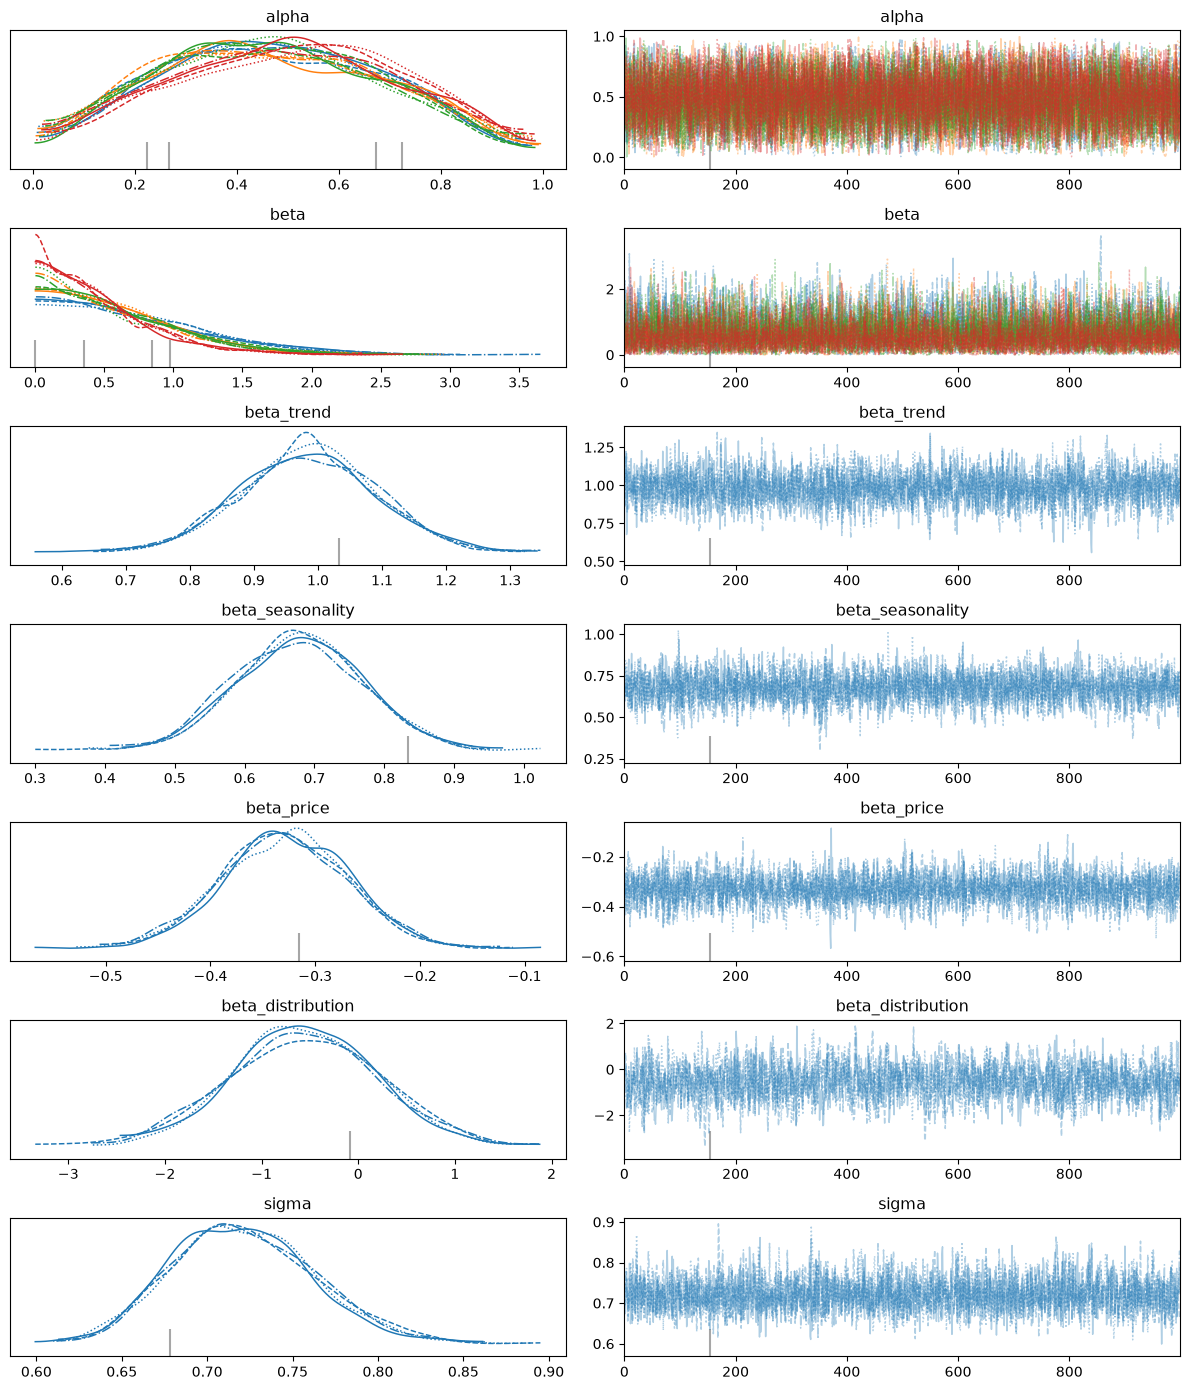

In [76]:
# Inspect the posterior visually
az.plot_trace(
    idata,
    var_names=[
        "alpha",
        "beta",
        "beta_trend",
        "beta_seasonality",
        "beta_price",
        "beta_distribution",
        "sigma"
    ]
)
plt.tight_layout()
plt.show()

In [78]:
diverging = idata.sample_stats["diverging"].values

print("Divergences per chain:", diverging.sum(axis=1))
print("Divergence locations:", np.argwhere(diverging))

Divergences per chain: [0 1 0 0]
Divergence locations: [[  1 154]]


The diagnostic above tells us that there was 1 chain with a divergence, and that the divergence occurred at draw 154 in the second chain.

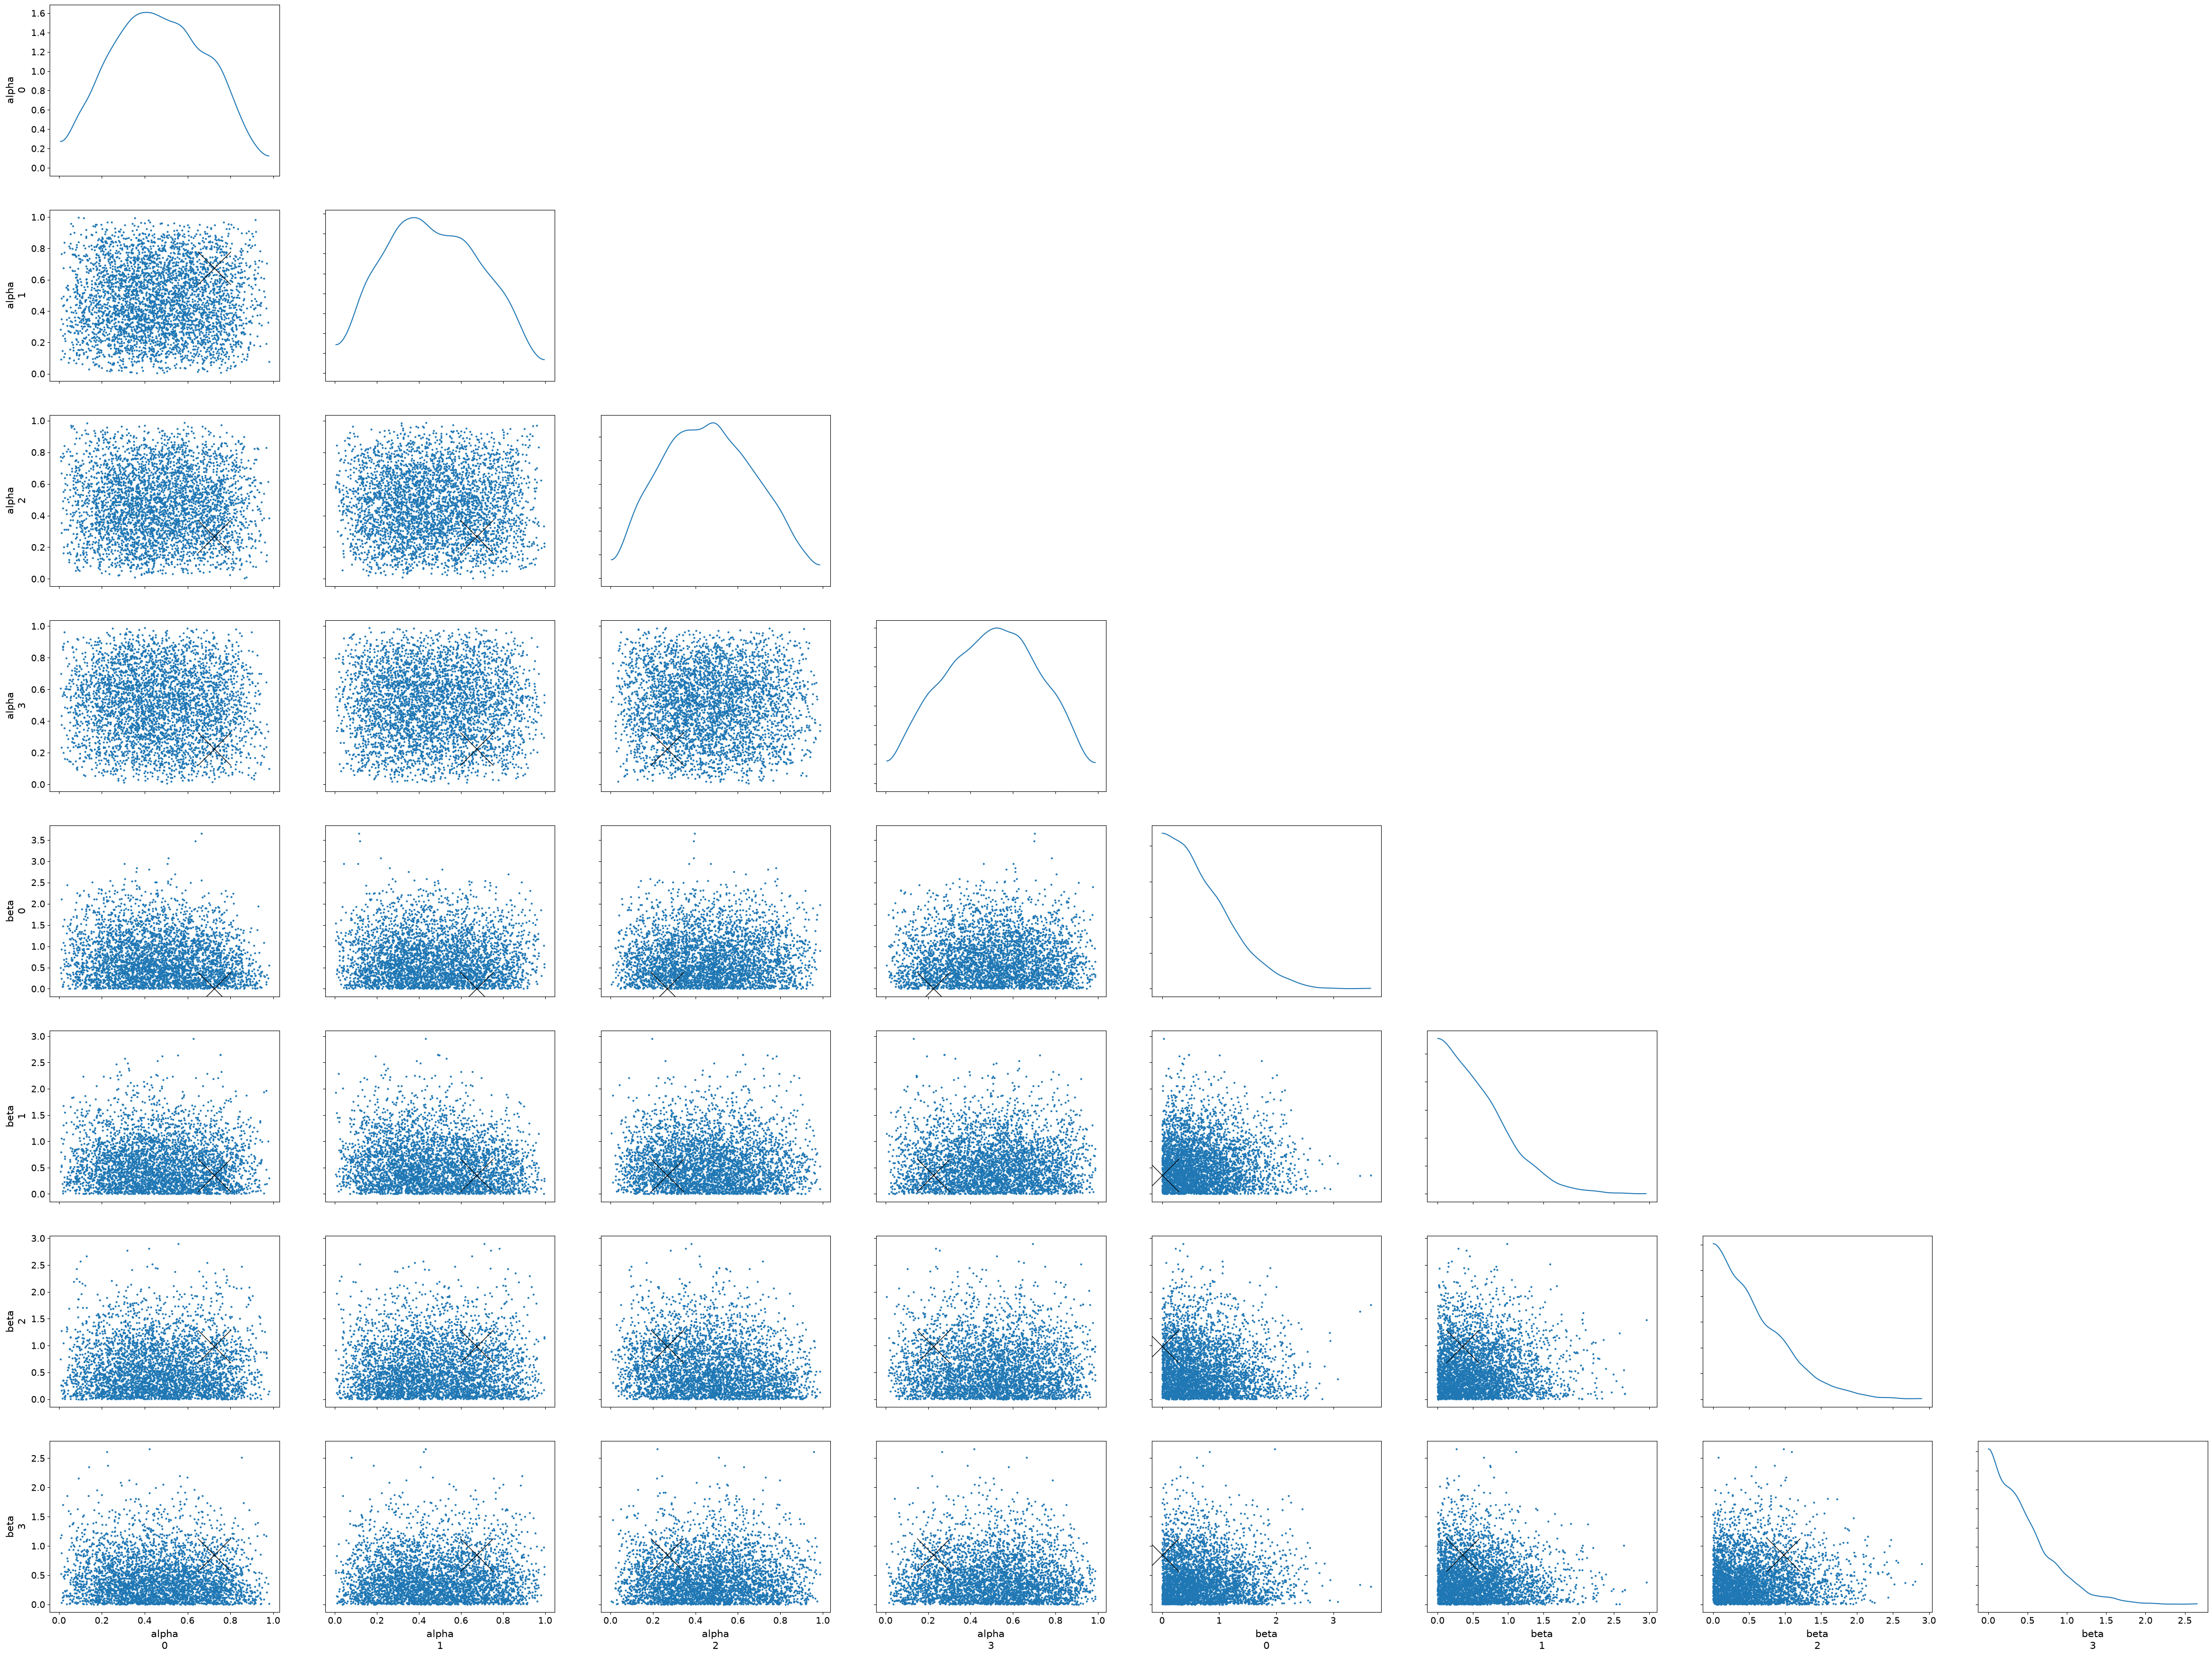

In [80]:
# Inspect the divergence
az.plot_pair(
    idata,
    var_names=["alpha", "beta"],
    divergences=True,
    divergences_kwargs={
        "color": "red",
        "marker": "x",
        "markersize": 50
    },
    marginals=True
)
plt.show()

### Why might the model struggle to distinguish the four channels' true carryover rates?

Consider:
- The amount of variation in each channel's weekly spend.
- The correlation between marketing channels.
- Whether alpha and beta can compensate for one another.
- How much information 156 weekly observations provide.

Answer: I don't think it's a matter of the information available - 156 weekly observations should be a fair amount to distinguish channel performance. I checked the correlation of the 4 channels spend and they are relatively independent. I think the beta and alpha can compensate for each other, though - because they are part of the same term "marketing effect" the model could be finding it difficult to separate the two. In order to separate the two we would likely have to re-specify the model to isolate the two terms.

Refinement:
Alpha is learned from the temporal pattern of spend and revenue. If spend doesn't vary enough over time, the model will struggle to distinguish whether its efffect is persistent or simply correlated with other components of revenue. In this case, alpha will remain weakly identified.

In [89]:
for i, channel in enumerate(channels):
    alpha_draws = idata.posterior["alpha"].isel(alpha_dim_0=i).values.flatten()
    beta_draws = idata.posterior["beta"].isel(beta_dim_0=i).values.flatten()

    correlation = np.corrcoef(alpha_draws, beta_draws)[0, 1]
    print(f"{channel}: {correlation:.3f}")

tv: -0.104
search: -0.098
social: -0.119
display: -0.021


The output above tells us that the draws between alpha and beta **posteriors** are not highly correlated, and the plot below shows that the posterior distribution for alpha is quite similar to the prior. This tells us that our data does not have a high quantity of information to update the prior for alpha.

Sampling: [alpha, beta, beta_distribution, beta_holiday, beta_price, beta_promotion, beta_seasonality, beta_trend, intercept, revenue_obs, sigma]


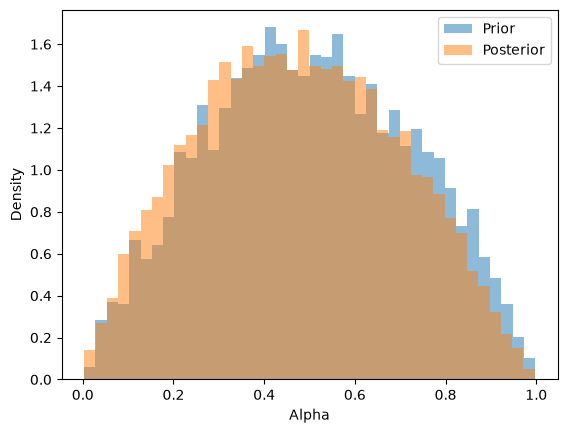

In [95]:
with mmm:
    prior_idata = pm.sample_prior_predictive(
        samples=1000,
        random_seed=42
    )

prior_alpha = prior_idata.prior["alpha"].values.flatten()
posterior_alpha = idata.posterior["alpha"].values.flatten()

plt.hist(prior_alpha, bins=40, density=True, alpha=0.5, label="Prior")
plt.hist(posterior_alpha, bins=40, density=True, alpha=0.5, label="Posterior")
plt.xlabel("Alpha")
plt.ylabel("Density")
plt.legend()
plt.show()

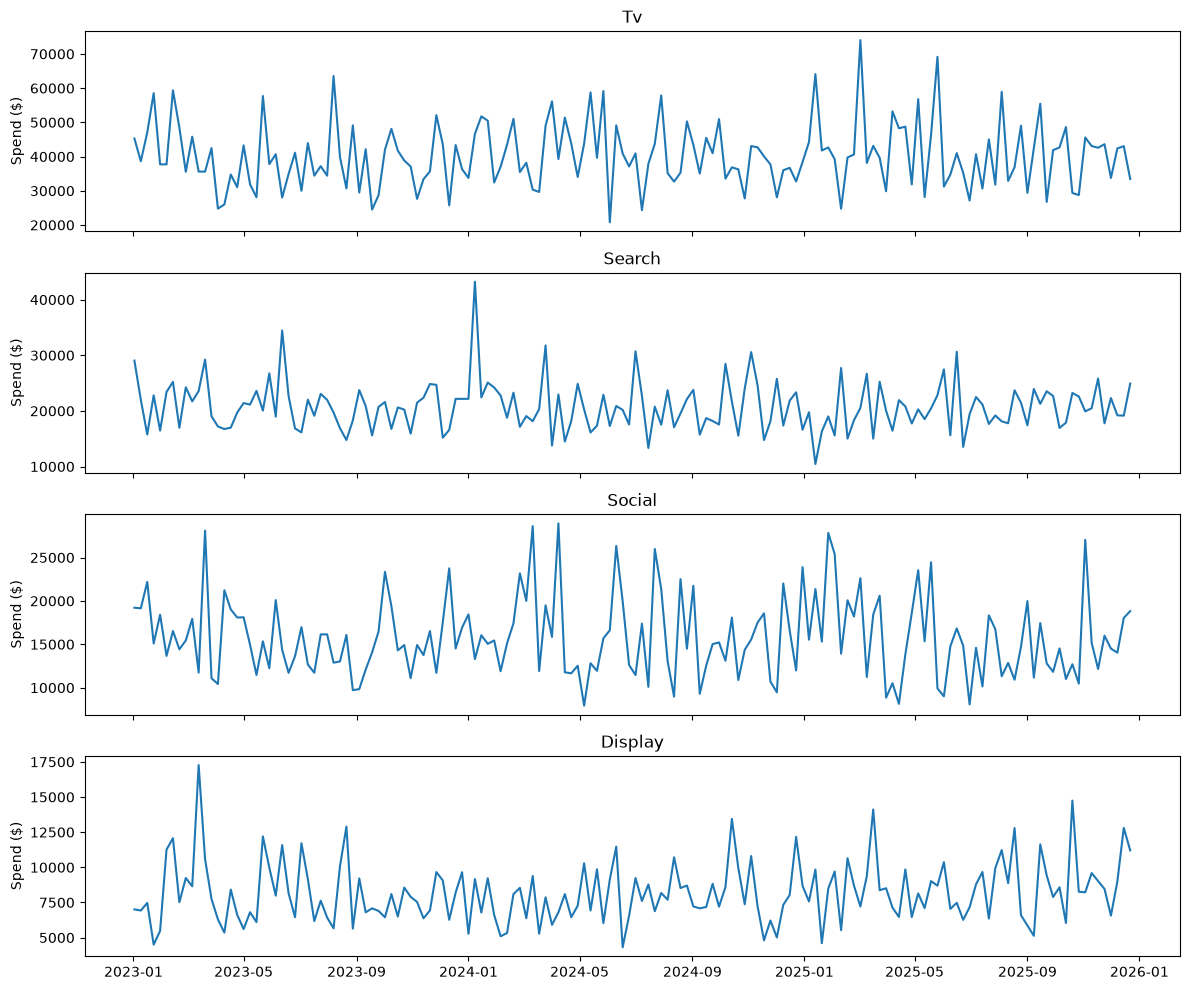

In [97]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for i, channel in enumerate(channels):
    axes[i].plot(pd.to_datetime(df["date"]), df[f"{channel}_spend"])
    axes[i].set_title(channel.title())
    axes[i].set_ylabel("Spend ($)")

plt.tight_layout()
plt.show()

Examining the spend patterns, we note that it's not an issue of spend being static - there appears to be weekly variation in spend.

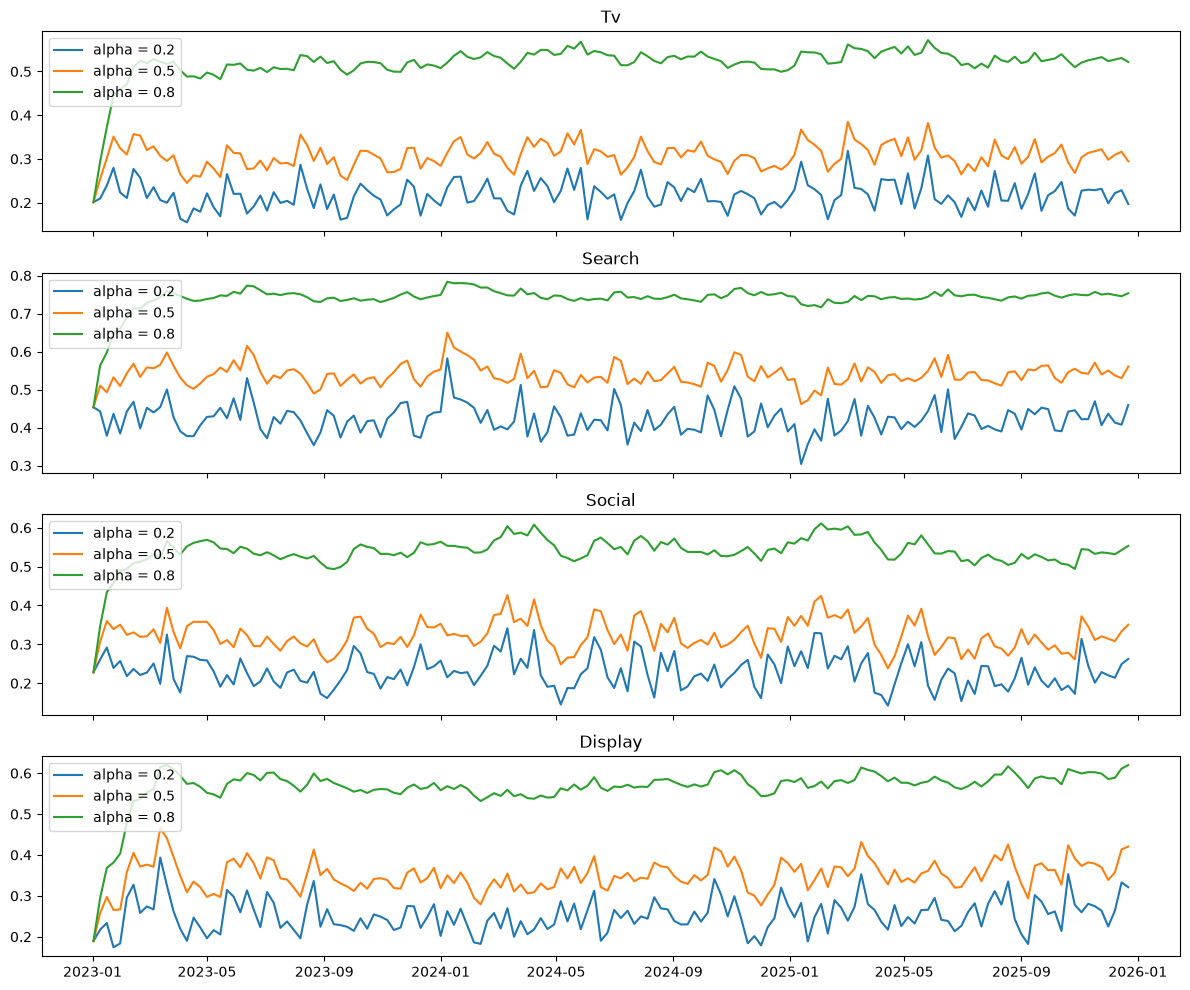

In [99]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for i, channel in enumerate(channels):
    x = spend[channel]

    for alpha_value in [0.2, 0.5, 0.8]:
        adstock = geometric_adstock(x, alpha_value)
        saturation = hill_saturation(adstock, ec50[channel])

        axes[i].plot(
            pd.to_datetime(df["date"]),
            saturation,
            label=f"alpha = {alpha_value}"
        )

    axes[i].set_title(channel.title())
    axes[i].legend()

plt.tight_layout()
plt.show()

There also is significant difference in saturation given different levels of alpha, so it's not a matter of alpha not producing variance in saturation.

Sampling: [revenue_obs]


Output()

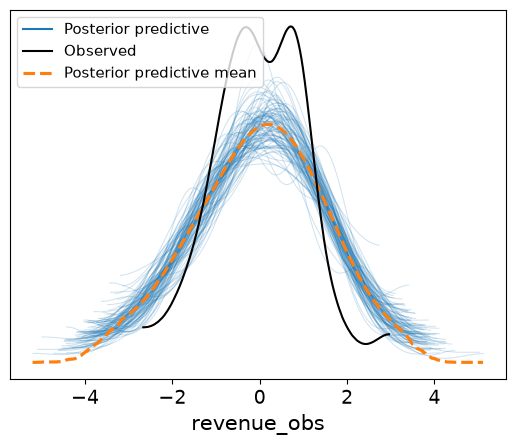

In [100]:
with mmm:
    ppc = pm.sample_posterior_predictive(
        idata,
        random_seed=42
    )

az.plot_ppc(ppc, num_pp_samples=100)
plt.show()

The posterior predictive distribution matches the observed distribution quite well, showing that the overall model is doing quite well at predicting the observed revenue values under the posterior, even though our specific alpha values are not recovered.

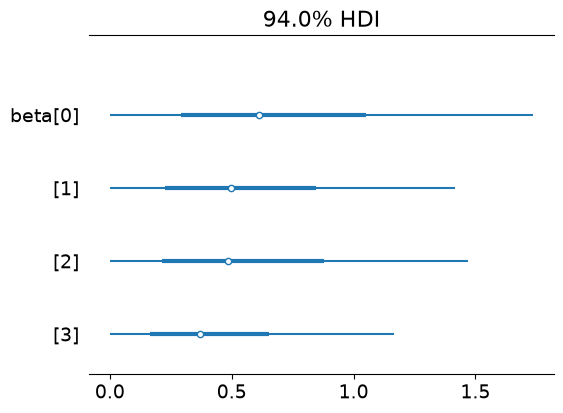

In [101]:
az.plot_forest(
    idata,
    var_names=["beta"],
    combined=True,
    hdi_prob=0.94
)
plt.show()

The above charts shows us that Beta coefficients also have high uncertainty. Our model has high uncertainty for both Alpha and Beta coefficients, again pointing to the weak identifiability given our observed data.

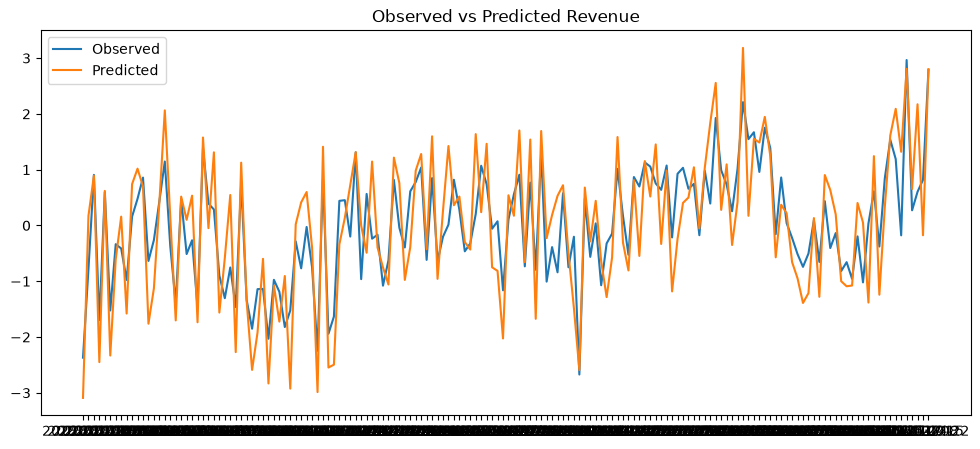

In [102]:
predicted = (
    ppc.posterior_predictive["revenue_obs"]
    .mean(dim=("chain", "draw"))
    .values
    .flatten()
)

observed = y

plt.figure(figsize=(12, 5))
plt.plot(df["date"], observed, label="Observed")
plt.plot(df["date"], predicted, label="Predicted")
plt.legend()
plt.title("Observed vs Predicted Revenue")
plt.show()

Another visualization to show that the posterior is predicting revenue quite well, despite alpha and beta being weakly identifiable.

# Diagnostics

Our goal is to isolate one question:
**Is uncertainty in alpha making it difficult for the model to estimate the channel contribution coefficients (beta)?**

In our synthetic dataset, we know the true alpha values:
| Channel | True alpha |
| --- | --- |
| TV | 0.65
| Search | 0.25
| Social | 0.45
| Display | 0.35

In a real MMM, we wouldn't know these values. But because this is synthetic data, we can use them as a diagnostic benchmark.

## Step 1. Modify the model
Instead of sampling alpha from a Beta distribution, we'll use the known values as constants.

In [103]:
# Step 2. Use the Hill saturation transformation
with pm.Model() as mmm_fixed_alpha:

    # Baseline
    intercept = pm.Normal("intercept", mu=0, sigma=1)

    # Adstock decay parameters, one per channel (CHANGE THIS LINE)
    alpha = [0.65, 0.25, 0.45, 0.35]

    # Channel contribution coefficients
    beta = pm.HalfNormal("beta", sigma=1, shape=len(channels))

    # Trend and seasonality
    beta_trend = pm.Normal("beta_trend", mu=0, sigma=1)
    beta_seasonality = pm.Normal("beta_seasonality", mu=0, sigma=1)

    # Control coefficients
    beta_price = pm.Normal("beta_price", mu=0, sigma=1)
    beta_distribution = pm.Normal("beta_distribution", mu=0, sigma=1)
    beta_promotion = pm.Normal("beta_promotion", mu=0, sigma=1)
    beta_holiday = pm.Normal("beta_holiday", mu=0, sigma=1)

    # Residual standard deviation
    sigma = pm.HalfNormal("sigma", sigma=1)

    # Calculate marketing effect
    channel_contributions = []
    
    for i, channel in enumerate(channels):
    
        # Recursive geometric adstock
        x = spend[channel]
        adstock_values = [x[0]]
        for t in range(1, n):
            adstock_values += [x[t] + alpha[i] * adstock_values[t-1]]
    
            # Stack the array
        adstock = pm.math.stack(adstock_values)
    
        # Hill saturation (shape fixed at 1)
        saturation = adstock / (adstock + ec50[channel])
    
        # Channel contribution
        contribution = beta[i] * saturation
        channel_contributions.append(contribution)
    
    # Combine all channel contributions - stack the array, then sum
    marketing_effect = pm.math.stack(channel_contributions).sum(axis=0)

    # Define revenue for our model
    mu = (
        intercept
        + marketing_effect
        + beta_trend * trend
        + beta_seasonality * seasonality
        + beta_price * price
        + beta_promotion * promotion
        + beta_distribution + distribution
        + beta_holiday * holiday
    )
    
    revenue_obs = pm.Normal("revenue_obs", mu=mu, sigma=sigma, observed=y)

In [104]:
# Refit the new model:
with mmm_fixed_alpha:
    idata_fixed_alpha = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=4,
        target_accept=0.90,
        random_seed=42
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta, beta_trend, beta_seasonality, beta_price, beta_distribution, beta_promotion, beta_holiday, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 53 seconds.


In [106]:
# Inspect convergence
summary = az.summary(idata_fixed_alpha, var_names=[
    "intercept",
    "beta",
    "beta_trend",
    "beta_seasonality",
    "beta_price",
    "beta_distribution",
    "beta_promotion",
    "beta_holiday",
    "sigma"
])

display(summary)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,-0.574,0.714,-1.950,0.729,0.016,0.012,2061.0,1859.0,1.0
beta[0],0.725,0.541,0.000,1.699,0.008,0.008,2345.0,1416.0,1.0
beta[1],0.638,0.472,0.000,1.464,0.008,0.008,2336.0,1451.0,1.0
beta[2],0.624,0.466,0.000,1.477,0.007,0.007,2609.0,1333.0,1.0
beta[3],0.470,0.384,0.002,1.165,0.006,0.006,2666.0,1654.0,1.0
beta_trend,0.987,0.107,0.781,1.181,0.002,0.002,3316.0,2997.0,1.0
beta_seasonality,0.679,0.088,0.504,0.834,0.001,0.001,3509.0,2951.0,1.0
beta_price,-0.330,0.058,-0.437,-0.219,0.001,0.001,4360.0,2471.0,1.0
beta_distribution,-0.539,0.726,-1.932,0.788,0.016,0.013,2096.0,2079.0,1.0
beta_promotion,0.434,0.121,0.206,0.662,0.002,0.002,4281.0,2853.0,1.0


The posterior summary passes basic checks:
* rhat = 1.0 > chains converged to the same distribution
* ESS >=400 - we have a fair enough number of independent samples in our effective sample size
* MCSE - small relative to coefficient SD


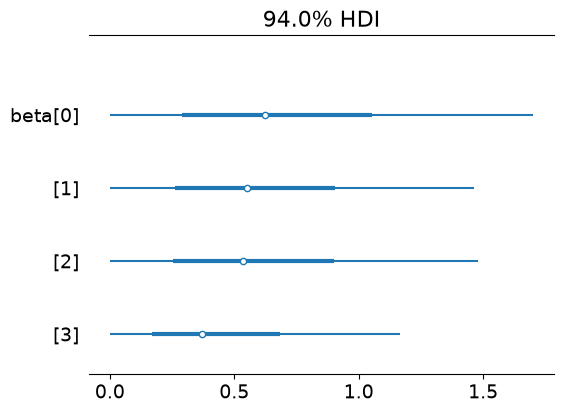

In [108]:
az.plot_forest(
    idata_fixed_alpha,
    var_names=["beta"],
    combined=True,
    hdi_prob=0.94
)
plt.show()

This output is very telling - it tells us that the uncertainty in alpha does not appear to be contributing to the uncertainty in beta. This is revealed by the fact that when we provide the oracle values for alpha in our model, the uncertainty for beta does not improve.

**What might explain this continued to uncertainty in identifying beta?**

I'd investigate three possibilities:
1. Limited signal-to-noise ratio: Marketing contributions may be relatively small compared with other sources of revenue variation.
2. Confounding with other predictors: Trend, seasonality, and controls may explain variation that could otherwise help identify marketing effects.
3. Weak channel-level identification: Even with known adstock rates, the data may not clearly distinguish the individual channel contributions.

In [111]:
true_marketing = sum(
    df_oracle[f"{channel}_contribution_true"]
    for channel in channels
)

print("Revenue standard deviation:", df["revenue"].std())
print("Marketing contribution standard deviation:", true_marketing.std())
print("Marketing contribution mean:", true_marketing.mean())

Revenue standard deviation: 17722.29761707729
Marketing contribution standard deviation: 2298.905780323164
Marketing contribution mean: 45876.691163420415


In [113]:
for channel in channels:
    contribution = df_oracle[f"{channel}_contribution_true"]

    print(
        f"{channel}: "
        f"mean = {contribution.mean():.2f}, "
        f"std = {contribution.std():.2f}"
    )

tv: mean = 17366.14, std = 1312.83
search: mean = 15346.01, std = 1300.37
social: mean = 8476.94, std = 1079.11
display: mean = 4687.59, std = 622.39


In [115]:
for channel in channels:
    adstock = df_oracle[f"{channel}_adstock_true"]
    saturation = adstock / (adstock + ec50[channel])

    print(
        f"{channel}: "
        f"mean saturation = {saturation.mean():.3f}, "
        f"min = {saturation.min():.3f}, "
        f"max = {saturation.max():.3f}"
    )

tv: mean saturation = 0.386, min = 0.201, max = 0.451
search: mean saturation = 0.438, min = 0.326, max = 0.591
social: mean saturation = 0.303, min = 0.215, max = 0.409
display: mean saturation = 0.293, min = 0.189, max = 0.423


In [117]:
saturated_data = pd.DataFrame({
    channel: (
        df_oracle[f"{channel}_adstock_true"] /
        (df_oracle[f"{channel}_adstock_true"] + ec50[channel])
    )
    for channel in channels
})

print(saturated_data.corr().round(2))

           tv  search  social  display
tv       1.00   -0.07    0.11     0.25
search  -0.07    1.00   -0.13     0.14
social   0.11   -0.13    1.00    -0.03
display  0.25    0.14   -0.03     1.00


In [118]:
diagnostic_data = saturated_data.copy()

diagnostic_data["trend"] = trend
diagnostic_data["seasonality"] = seasonality
diagnostic_data["price"] = price
diagnostic_data["distribution"] = distribution
diagnostic_data["promotion"] = promotion
diagnostic_data["holiday"] = holiday

print(diagnostic_data.corr().round(2))

                tv  search  social  display  trend  seasonality  price  \
tv            1.00   -0.07    0.11     0.25   0.28         0.17   0.00   
search       -0.07    1.00   -0.13     0.14  -0.06         0.02   0.07   
social        0.11   -0.13    1.00    -0.03  -0.06         0.27  -0.10   
display       0.25    0.14   -0.03     1.00   0.20        -0.05  -0.05   
trend         0.28   -0.06   -0.06     0.20   1.00        -0.26   0.08   
seasonality   0.17    0.02    0.27    -0.05  -0.26         1.00  -0.09   
price         0.00    0.07   -0.10    -0.05   0.08        -0.09   1.00   
distribution -0.03    0.01    0.10     0.12  -0.09        -0.01  -0.08   
promotion    -0.08   -0.00    0.15     0.03  -0.02         0.04  -0.08   
holiday      -0.14    0.08    0.05     0.03   0.22        -0.30  -0.10   

              distribution  promotion  holiday  
tv                   -0.03      -0.08    -0.14  
search                0.01      -0.00     0.08  
social                0.10       0.15 

<Axes: >

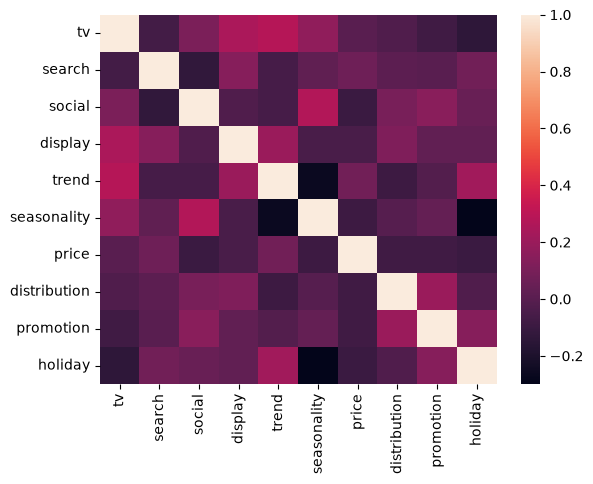

In [119]:
import seaborn as sns

sns.heatmap(diagnostic_data.corr().round(2))

In [ ]:
# Step 4. Estimate channel coefficients, baseline, trend, seasonality, controls, and residual noise